# TC5061 · Actividad 2 - Notebook Baseline

**Alumno:** Victor Yoguel Salazar Alanis A01797950  
**Curso:** TC5061 - Operaciones de Aprendizaje Automático (MLOps)

Tecnológico de Monterrey

## Objetivo
Recorrer el flujo básico de un proyecto de *Machine Learning* (carga, partición, EDA, limpieza, modelo base, evaluación y registro en **MLflow Tracking**), dejando evidencia reproducible del punto de partida.

## Contenido
1. Carga y descripción del dataset
2. Partición de los datos (70/15/15)
3. Análisis exploratorio (EDA) sobre entrenamiento
4. Limpieza de datos
5. Modelo base (*baseline*)
6. Evaluación del modelo
7. Registro del experimento en MLflow
8. Reflexión sobre MLOps
9. Referencias
10. Declaración de uso de inteligencia artificial

## 0. Configuración del entorno

In [1]:
# Librerías estándar y de análisis
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Scikit-learn: partición, preprocesamiento, modelos y métricas
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# MLflow para el registro del experimento
import mlflow
from mlflow.models import infer_signature

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

# Semilla global para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f"Python {platform.python_version()} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | mlflow {mlflow.__version__}")

Python 3.12.10 | pandas 3.0.6 | scikit-learn 1.9.1 | mlflow 3.16.1


In [2]:
# ===================== CONFIGURACIÓN DEL EXPERIMENTO =====================
# Raíz del proyecto (funciona si el notebook se abre desde /notebooks o desde la raíz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RED_PATH = ROOT / "data" / "raw" / "winequality-red.csv"
WHITE_PATH = ROOT / "data" / "raw" / "winequality-white.csv"
TARGET = "quality"

# Partición 70 % entrenamiento / 15 % validación / 15 % prueba
VAL_SIZE = 0.15
TEST_SIZE = 0.15
EXPERIMENT_NAME = "TC5061_Actividad2_Baseline"

FIG_DIR = ROOT / "reports" / "figures"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

assert RED_PATH.exists() and WHITE_PATH.exists(), "Faltan los CSV de Wine Quality en data/raw/."

## 1. Carga y descripción del dataset

**Dataset:** Wine Quality ([UCI Machine Learning Repository #186](https://archive.ics.uci.edu/dataset/186/wine+quality))

**Contexto:** cada registro es una muestra de vino *Vinho Verde* portugués (tinto o blanco) descrita por 11 mediciones fisicoquímicas de laboratorio. La variable objetivo `quality` es la mediana de la calificación sensorial (escala 0-10) otorgada por al menos tres catadores expertos.

**Variable objetivo:** `quality`. Se aborda como **regresión** porque es una escala numérica ordenada; el error se interpreta directamente en puntos de calidad. (Una alternativa común es binarizarla en "bueno" ≥ 7 y tratarla como clasificación.)

El dataset se distribuye en dos archivos (tinto y blanco) separados por `;`. Se combinan en un solo DataFrame agregando la columna `tipo`, que permite analizar si el tipo de vino influye en la calidad.

In [3]:
# Carga de los datos crudos: los CSV de UCI usan ';' como separador.
# Se combinan tinto y blanco en un solo DataFrame con la columna 'tipo'.
df_red = pd.read_csv(RED_PATH, sep=";").assign(tipo="tinto")
df_white = pd.read_csv(WHITE_PATH, sep=";").assign(tipo="blanco")
df_raw = pd.concat([df_red, df_white], ignore_index=True)
print(f"Tinto: {len(df_red):,} | Blanco: {len(df_white):,} | Total: {df_raw.shape[0]:,} registros, {df_raw.shape[1]} variables")
df_raw.head()

Tinto: 1,599 | Blanco: 4,898 | Total: 6,497 registros, 13 variables


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,tinto
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,tinto
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,tinto
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto


In [4]:
# Estructura general: tipos de dato y no-nulos por columna
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  tipo                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 697.3 KB


In [5]:
# Resumen por variable: tipo, valores únicos, % de nulos y un ejemplo
def resumen_variables(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_unicos": df.nunique(),
        "pct_nulos": (df.isna().mean() * 100).round(2),
        "ejemplo": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
    })

resumen_variables(df_raw)

,dtype,n_unicos,pct_nulos,ejemplo
fixed acidity,float64,106,0.0,7.4
volatile acidity,float64,187,0.0,0.7
citric acid,float64,89,0.0,0.0
residual sugar,float64,316,0.0,1.9
chlorides,float64,214,0.0,0.076
free sulfur dioxide,float64,135,0.0,11.0
total sulfur dioxide,float64,276,0.0,34.0
density,float64,998,0.0,0.9978
pH,float64,108,0.0,3.51
sulphates,float64,111,0.0,0.56


### Diccionario de variables

| Variable | Tipo | Significado |
|---|---|---|
| `fixed acidity` | numérica (g/L) | Acidez fija (ácido tartárico): ácidos no volátiles del vino |
| `volatile acidity` | numérica (g/L) | Acidez volátil (ácido acético); en exceso da sabor a vinagre |
| `citric acid` | numérica (g/L) | Ácido cítrico; aporta frescura y sabor en pequeñas cantidades |
| `residual sugar` | numérica (g/L) | Azúcar que queda tras la fermentación |
| `chlorides` | numérica (g/L) | Cloruros (sal) en el vino |
| `free sulfur dioxide` | numérica (mg/L) | SO₂ libre; previene crecimiento microbiano y oxidación |
| `total sulfur dioxide` | numérica (mg/L) | SO₂ total (libre + ligado); en exceso se percibe en nariz y boca |
| `density` | numérica (g/cm³) | Densidad; depende del alcohol y el azúcar |
| `pH` | numérica | Acidez en escala 0-14 (la mayoría de los vinos: 3-4) |
| `sulphates` | numérica (g/L) | Sulfatos (aditivo); contribuyen al SO₂ |
| `alcohol` | numérica (% vol.) | Grado alcohólico |
| `tipo` | categórica | Tinto o blanco (agregada al combinar los dos archivos) |
| **`quality`** | **objetivo (0-10)** | **Mediana de la calificación sensorial de ≥ 3 catadores** |

## 2. Partición de los datos (70/15/15)

La partición se hace **antes del EDA** y toda la exploración usa únicamente el set de entrenamiento: mirar el set de prueba sesga las decisiones de modelado y vuelve optimista la estimación final del error (*data snooping bias*). **Validación** se usa para comparar alternativas durante el desarrollo y **prueba** se reserva para la estimación final.

Se usa `train_test_split` con `stratify=quality` (en dos pasos: 70/30 y luego 30 → 15/15) para que la **distribución del objetivo se mantenga** en las tres particiones. Las calidades extremas (3 y 9) tienen muy pocas muestras para repartirse entre tres particiones, así que **sólo para las etiquetas de estratificación** se agrupan con su vecina (`clip(4, 8)`); los datos no se modifican.

Antes de partir se aplican dos preparaciones que no dependen de estadísticas de los datos:
- **Tipos:** las 11 variables fisicoquímicas se leyeron como `float` y `quality` como `int` (correcto); `tipo` se convierte a `category`.
- **Duplicados:** se eliminan las filas duplicadas exactas; si una misma muestra cayera en entrenamiento y prueba, la evaluación estaría contaminada (*leakage*).

In [6]:
df = df_raw.copy()
cleaning_log = []  # bitácora de decisiones de calidad de datos

def log_step(paso: str, decision: str, antes: int, despues: int):
    cleaning_log.append({"paso": paso, "decision": decision, "filas_antes": antes, "filas_despues": despues})

# Tipos: sólo 'tipo' (object) requiere conversión a category
df["tipo"] = df["tipo"].astype("category")
log_step("Tipos", "Numéricas y quality bien tipadas al cargar; 'tipo' convertida a category", len(df), len(df))

# Duplicados: se eliminan ANTES de partir para evitar fuga entre particiones
antes = len(df)
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
log_step("Duplicados", f"Se eliminaron {n_dup} filas duplicadas exactas antes de la partición", antes, len(df))
print(f"Duplicados eliminados: {n_dup} | Registros restantes: {len(df):,}")

Duplicados eliminados: 1177 | Registros restantes: 5,320


In [7]:
# Partición estratificada por quality: 70/30 y luego el 30 % se divide a la mitad.
# Las clases 3 y 9 son demasiado raras para estratificarse solas (quality=9 tiene ~5
# muestras); se agrupan con su vecina SOLO en las etiquetas de estratificación.
strat = df[TARGET].clip(lower=4, upper=8)
df_train, df_temp = train_test_split(df, test_size=VAL_SIZE + TEST_SIZE,
                                     random_state=RANDOM_STATE, stratify=strat)
df_val, df_test = train_test_split(df_temp, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
                                   random_state=RANDOM_STATE,
                                   stratify=df_temp[TARGET].clip(lower=4, upper=8))
df_train, df_val, df_test = (d.reset_index(drop=True) for d in (df_train, df_val, df_test))
print(f"Train: {df_train.shape} ({len(df_train)/len(df):.0%}) | "
      f"Val: {df_val.shape} ({len(df_val)/len(df):.0%}) | "
      f"Test: {df_test.shape} ({len(df_test)/len(df):.0%})")

Train: (3724, 13) (70%) | Val: (798, 13) (15%) | Test: (798, 13) (15%)


In [8]:
# Verificación: la distribución de quality (%) se mantiene en las tres particiones
dist_target = pd.DataFrame({
    "completo": df[TARGET].value_counts(normalize=True),
    "train": df_train[TARGET].value_counts(normalize=True),
    "val": df_val[TARGET].value_counts(normalize=True),
    "test": df_test[TARGET].value_counts(normalize=True),
}).mul(100).round(2).sort_index().fillna(0)
dist_target

,completo,train,val,test
quality,,,,
3,0.56,0.48,0.88,0.63
4,3.87,3.95,3.51,3.88
5,32.93,32.95,32.96,32.83
6,43.67,43.66,43.61,43.73
7,16.09,16.08,16.17,16.04
8,2.78,2.79,2.76,2.76
9,0.09,0.08,0.13,0.13


## 3. Análisis exploratorio (EDA)

El EDA se realiza **únicamente con el set de entrenamiento** (`df_train`) para que ninguna decisión se base en datos de validación o prueba.

In [9]:
# Identificación de columnas numéricas y categóricas (excluyendo el target)
num_cols = df_train.drop(columns=[TARGET]).select_dtypes(include="number").columns.tolist()
cat_cols = df_train.drop(columns=[TARGET]).select_dtypes(exclude="number").columns.tolist()
print(f"Numéricas ({len(num_cols)}): {num_cols}")
print(f"Categóricas ({len(cat_cols)}): {cat_cols}")

Numéricas (11): ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Categóricas (1): ['tipo']


In [10]:
# Estadísticas descriptivas de las variables numéricas (incluye asimetría)
desc = df_train[num_cols].describe().T
desc["skew"] = df_train[num_cols].skew()
desc

,count,mean,std,min,25%,50%,75%,max,skew
fixed acidity,3724.0,7.233472,1.334191,4.20000,6.400000,7.0000,7.700000,15.90000,1.664234
volatile acidity,3724.0,0.343910,0.166553,0.08000,0.230000,0.3000,0.410000,1.33000,1.479758
citric acid,3724.0,0.317342,0.146705,0.00000,0.240000,0.3100,0.400000,1.66000,0.466003
residual sugar,3724.0,4.990306,4.453719,0.60000,1.800000,2.7000,7.400000,65.80000,1.877210
chlorides,3724.0,0.056686,0.036428,0.00900,0.038000,0.0470,0.066000,0.61100,5.241684
free sulfur dioxide,3724.0,29.889098,17.720528,1.00000,17.000000,28.0000,41.000000,289.00000,1.505837
total sulfur dioxide,3724.0,113.055451,56.073270,7.00000,74.000000,115.0000,152.000000,440.00000,0.052139
density,3724.0,0.994509,0.002969,0.98711,0.992147,0.9946,0.996705,1.03898,0.903220
pH,3724.0,3.223279,0.160386,2.72000,3.110000,3.2100,3.330000,4.01000,0.433354
sulphates,3724.0,0.532822,0.147535,0.22000,0.430000,0.5100,0.600000,1.98000,1.552522


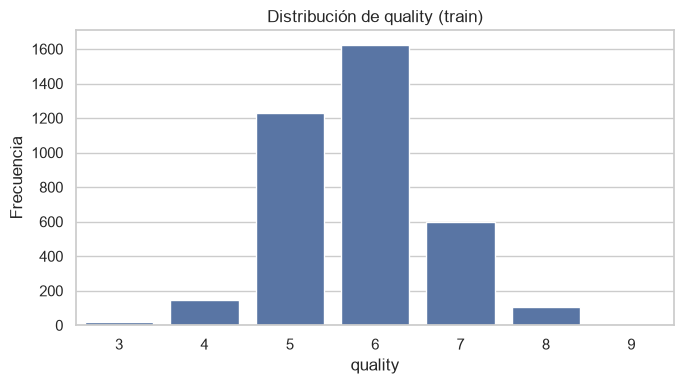

quality
3     0.48
4     3.95
5    32.95
6    43.66
7    16.08
8     2.79
9     0.08
Name: proportion, dtype: float64


In [11]:
# Distribución de la variable objetivo en entrenamiento
counts = df_train[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax)
ax.set(title=f"Distribución de {TARGET} (train)", xlabel=TARGET, ylabel="Frecuencia")
plt.tight_layout(); plt.savefig(FIG_DIR / "target_distribution.png", dpi=120); plt.show()
print((df_train[TARGET].value_counts(normalize=True).sort_index() * 100).round(2))

### 3.1 Análisis univariable

**Numéricas:** histograma con densidad KDE comparado contra la curva de una **distribución normal** con la misma media y desviación estándar. Donde la KDE se separa de la normal hay asimetría o colas pesadas (se anota el *skew* en cada título).

**Categórica (`tipo`):** gráfico de barras con la frecuencia de cada categoría.

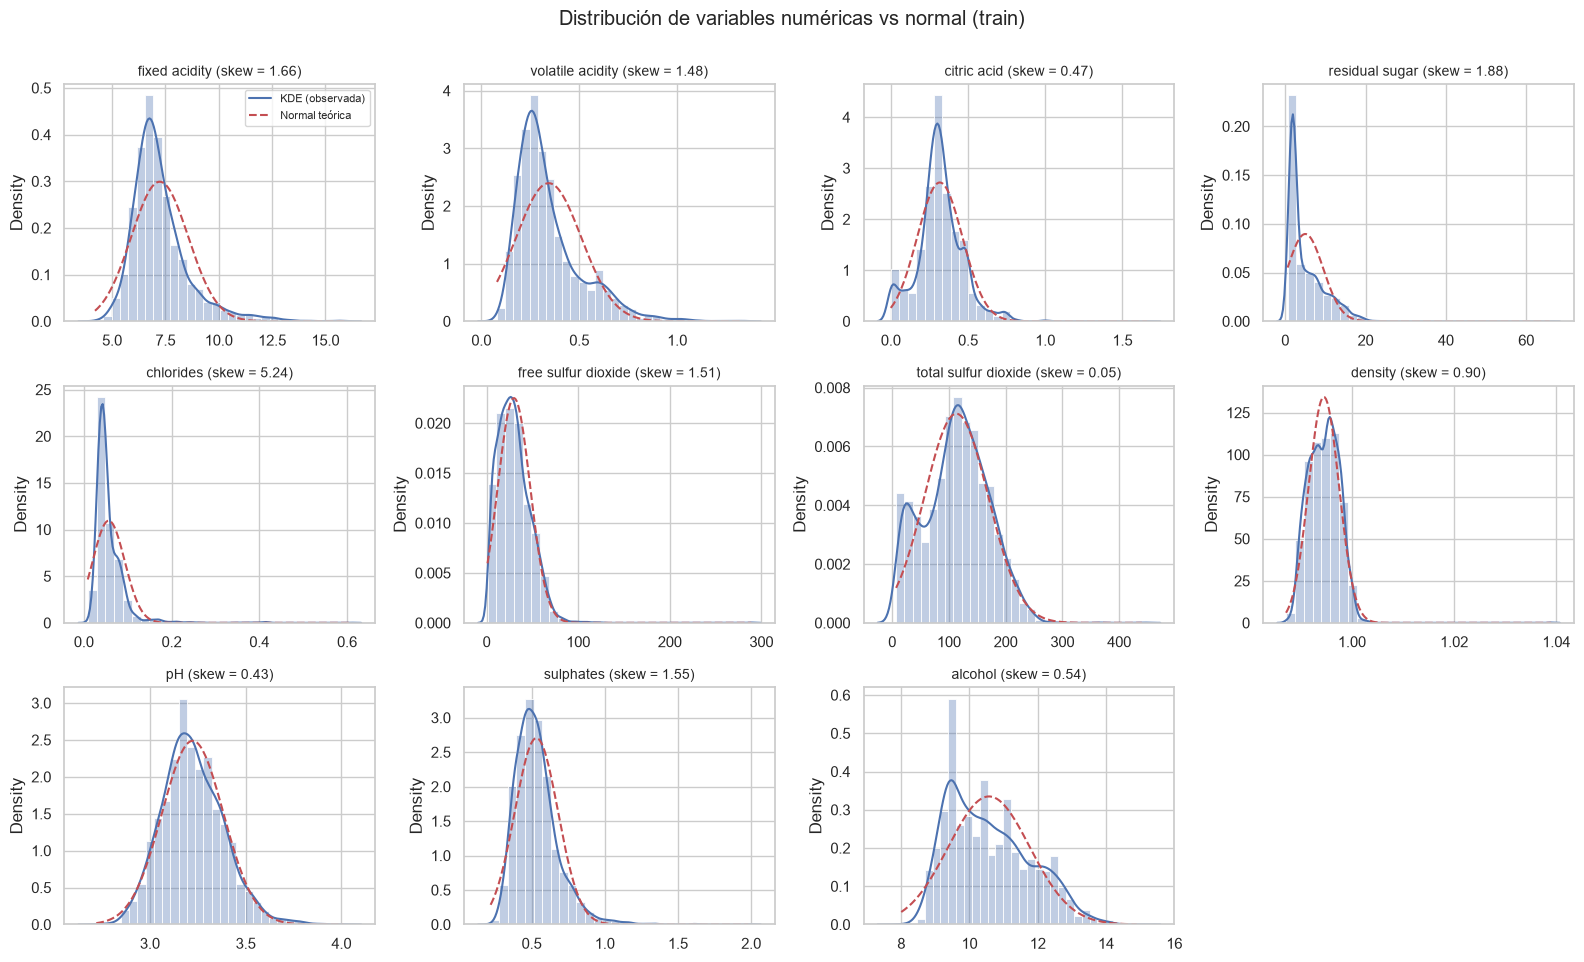

In [12]:
# Univariable numérico: distribución observada (histograma + KDE) vs normal teórica
n_rows = int(np.ceil(len(num_cols) / 4))
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 3.2 * n_rows), squeeze=False)
for ax, col in zip(axes.flat, num_cols):
    data = df_train[col].dropna()
    sns.histplot(data, bins=30, stat="density", alpha=0.35, ax=ax)
    sns.kdeplot(data, ax=ax, color="C0", lw=1.5, label="KDE (observada)")
    x = np.linspace(data.min(), data.max(), 200)
    ax.plot(x, stats.norm.pdf(x, data.mean(), data.std()), "r--", lw=1.5, label="Normal teórica")
    ax.set_title(f"{col} (skew = {data.skew():.2f})", fontsize=10)
    ax.set_xlabel("")
axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle("Distribución de variables numéricas vs normal (train)", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "univariate_numeric_vs_normal.png", dpi=120); plt.show()

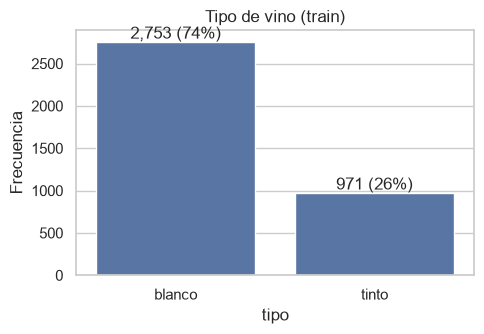

In [13]:
# Univariable categórico: frecuencia de cada tipo de vino
counts_tipo = df_train["tipo"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=counts_tipo.index.astype(str), y=counts_tipo.values, ax=ax)
for i, v in enumerate(counts_tipo.values):
    ax.text(i, v, f"{v:,} ({v/len(df_train):.0%})", ha="center", va="bottom")
ax.set(title="Tipo de vino (train)", xlabel="tipo", ylabel="Frecuencia")
plt.tight_layout(); plt.savefig(FIG_DIR / "univariate_tipo.png", dpi=120); plt.show()

### 3.2 Análisis bivariable

**Numéricas vs numéricas:** `sns.pairplot` autogenera la matriz de dispersión de todos los pares de variables (incluyendo `quality`), con las distribuciones en la diagonal. Se complementa con la matriz de correlación de Pearson, que resume la misma información en un solo número por par.

**Categórica vs numéricas:** para comparar una variable categórica contra una numérica las opciones usuales son *boxplot*, *violin plot* y *strip plot*. Se elige el **violin plot** porque, además de mediana y cuartiles (lo que muestra un boxplot), dibuja la **forma completa de la densidad** de cada grupo, lo que permite ver bimodalidades y colas; con sólo dos categorías (tinto/blanco) resulta muy legible.

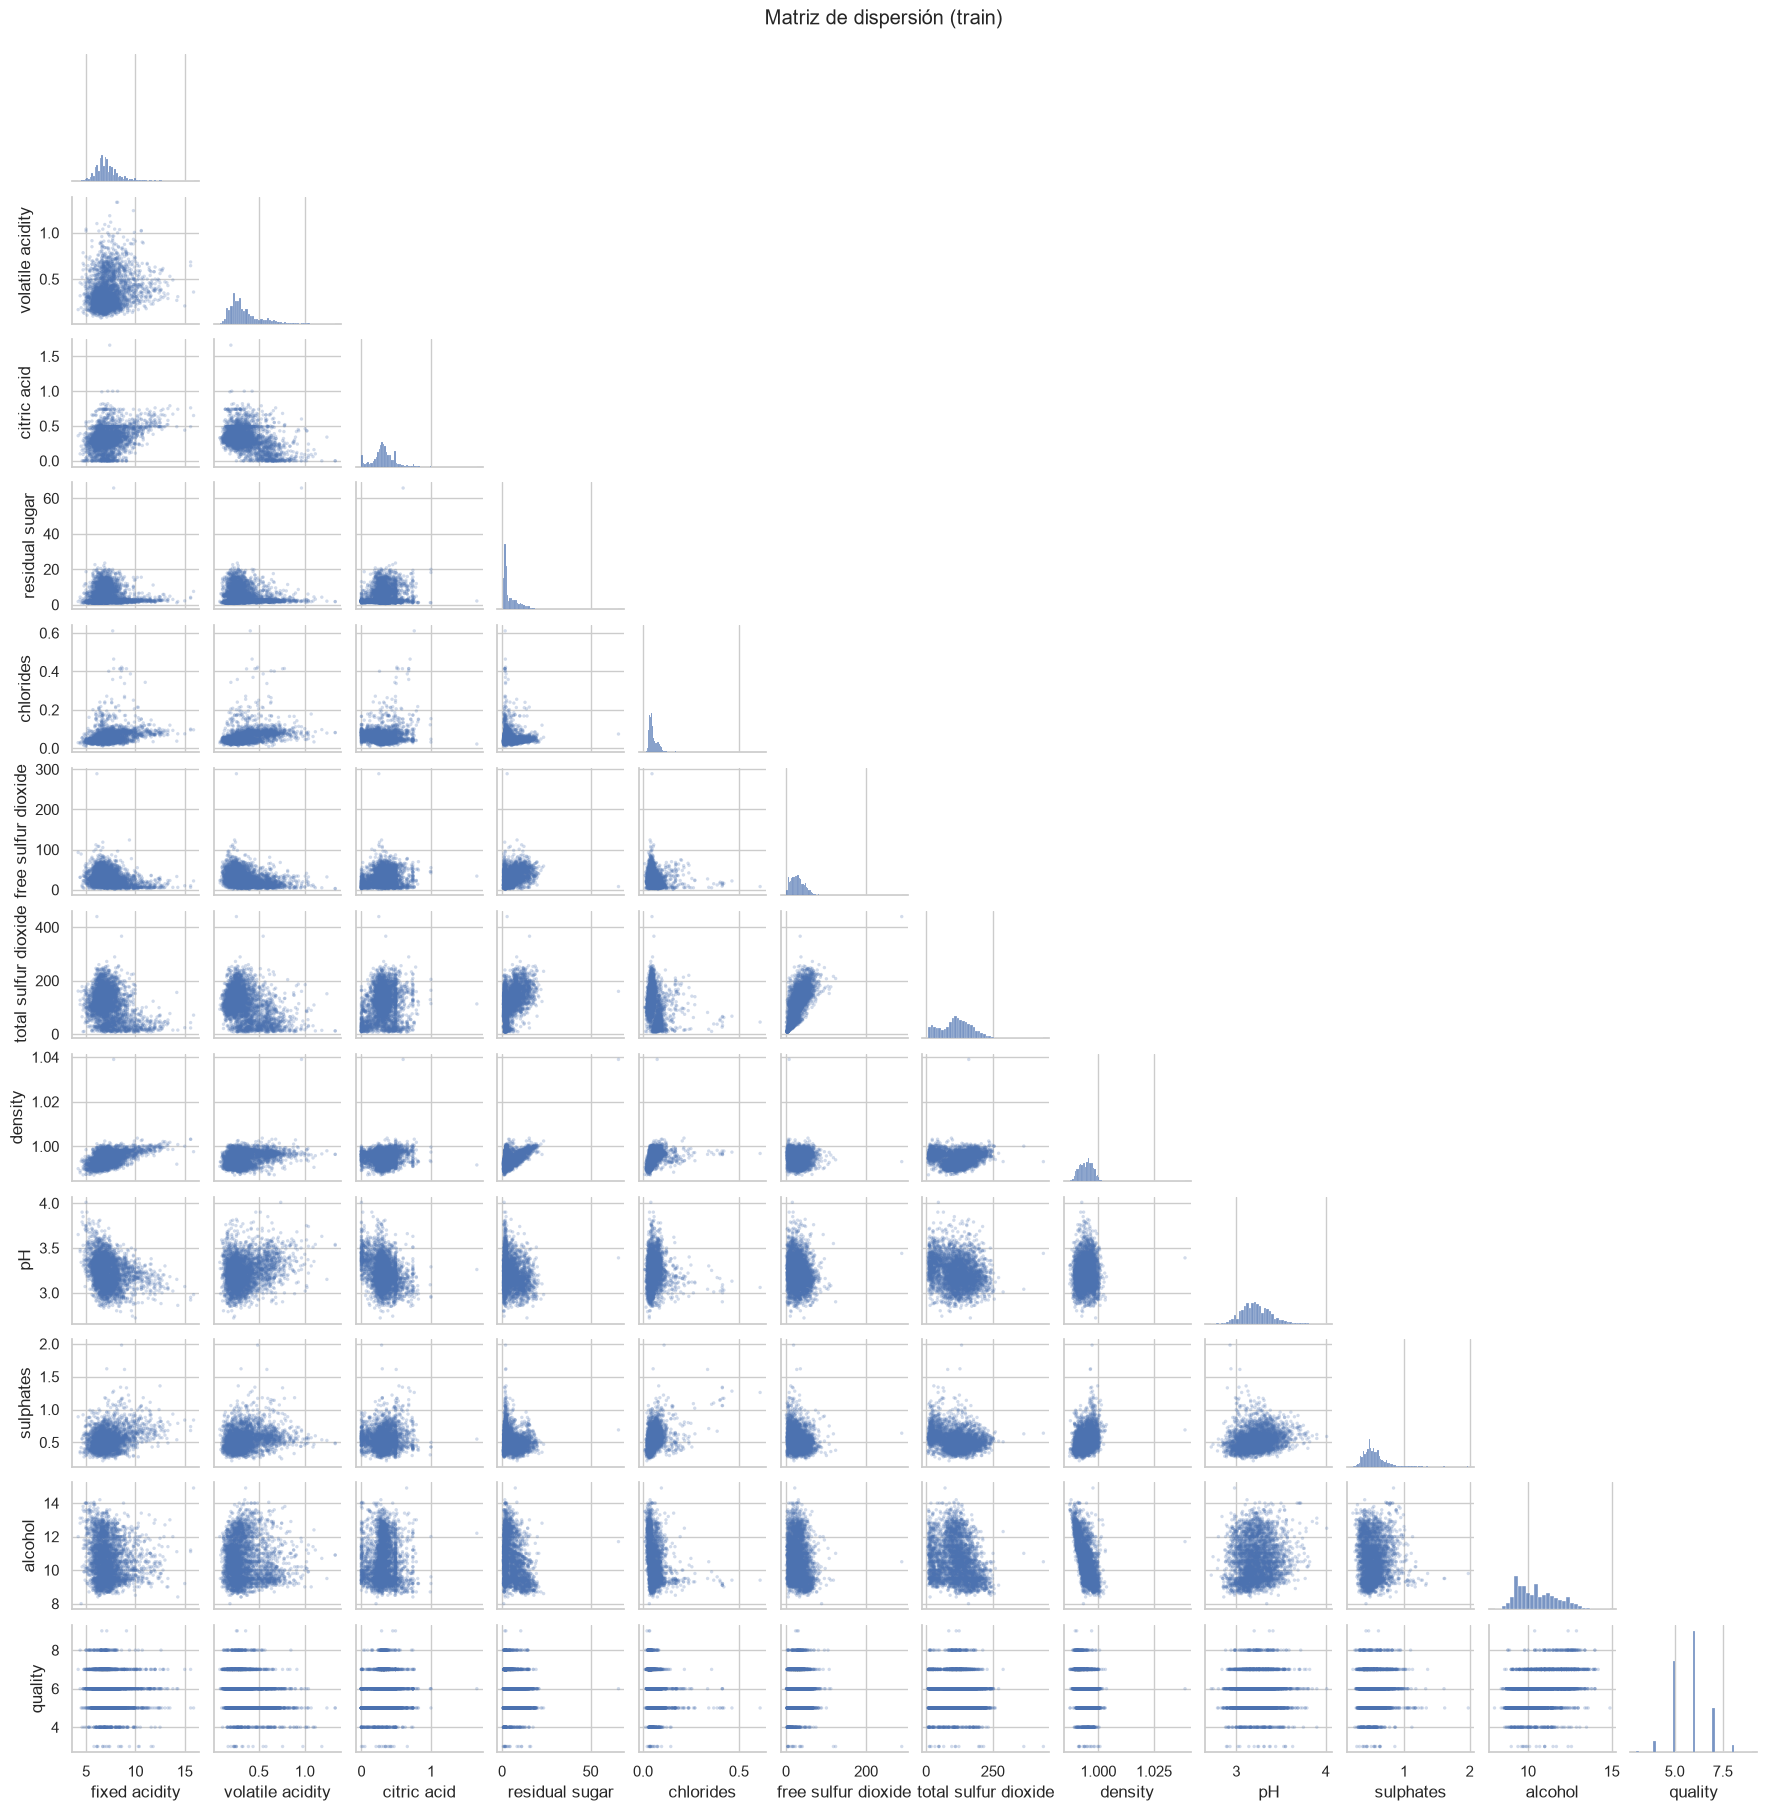

In [14]:
# Bivariable numérico: matriz de dispersión autogenerada (pairplot)
# corner=True omite la mitad redundante; la diagonal muestra cada distribución.
g = sns.pairplot(df_train[num_cols + [TARGET]], corner=True, diag_kind="hist",
                 plot_kws={"s": 6, "alpha": 0.25, "edgecolor": "none"}, height=1.5)
g.figure.suptitle("Matriz de dispersión (train)", y=1.01)
g.savefig(FIG_DIR / "bivariate_pairplot.png", dpi=90)
plt.show()

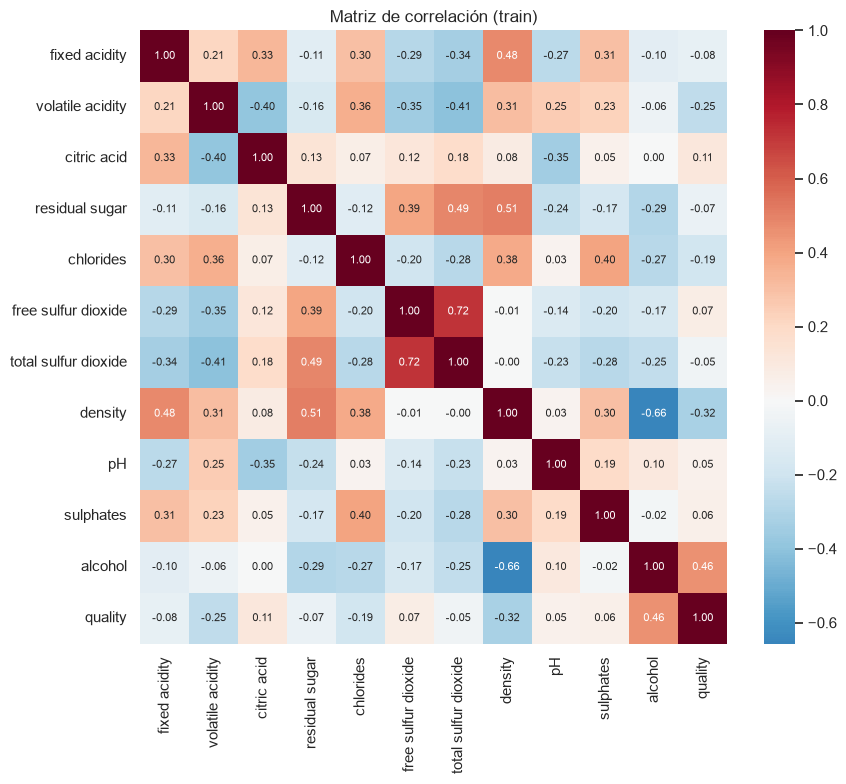

alcohol                 0.458
density                -0.324
volatile acidity       -0.254
chlorides              -0.189
citric acid             0.107
fixed acidity          -0.082
free sulfur dioxide     0.070
residual sugar         -0.067
sulphates               0.058
pH                      0.049
total sulfur dioxide   -0.047
Name: quality, dtype: float64

In [15]:
# Matriz de correlación (Pearson) entre numéricas y el target
corr = df_train[num_cols + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            annot_kws={"size": 8})
ax.set_title("Matriz de correlación (train)")
plt.tight_layout(); plt.savefig(FIG_DIR / "correlation_matrix.png", dpi=120); plt.show()
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

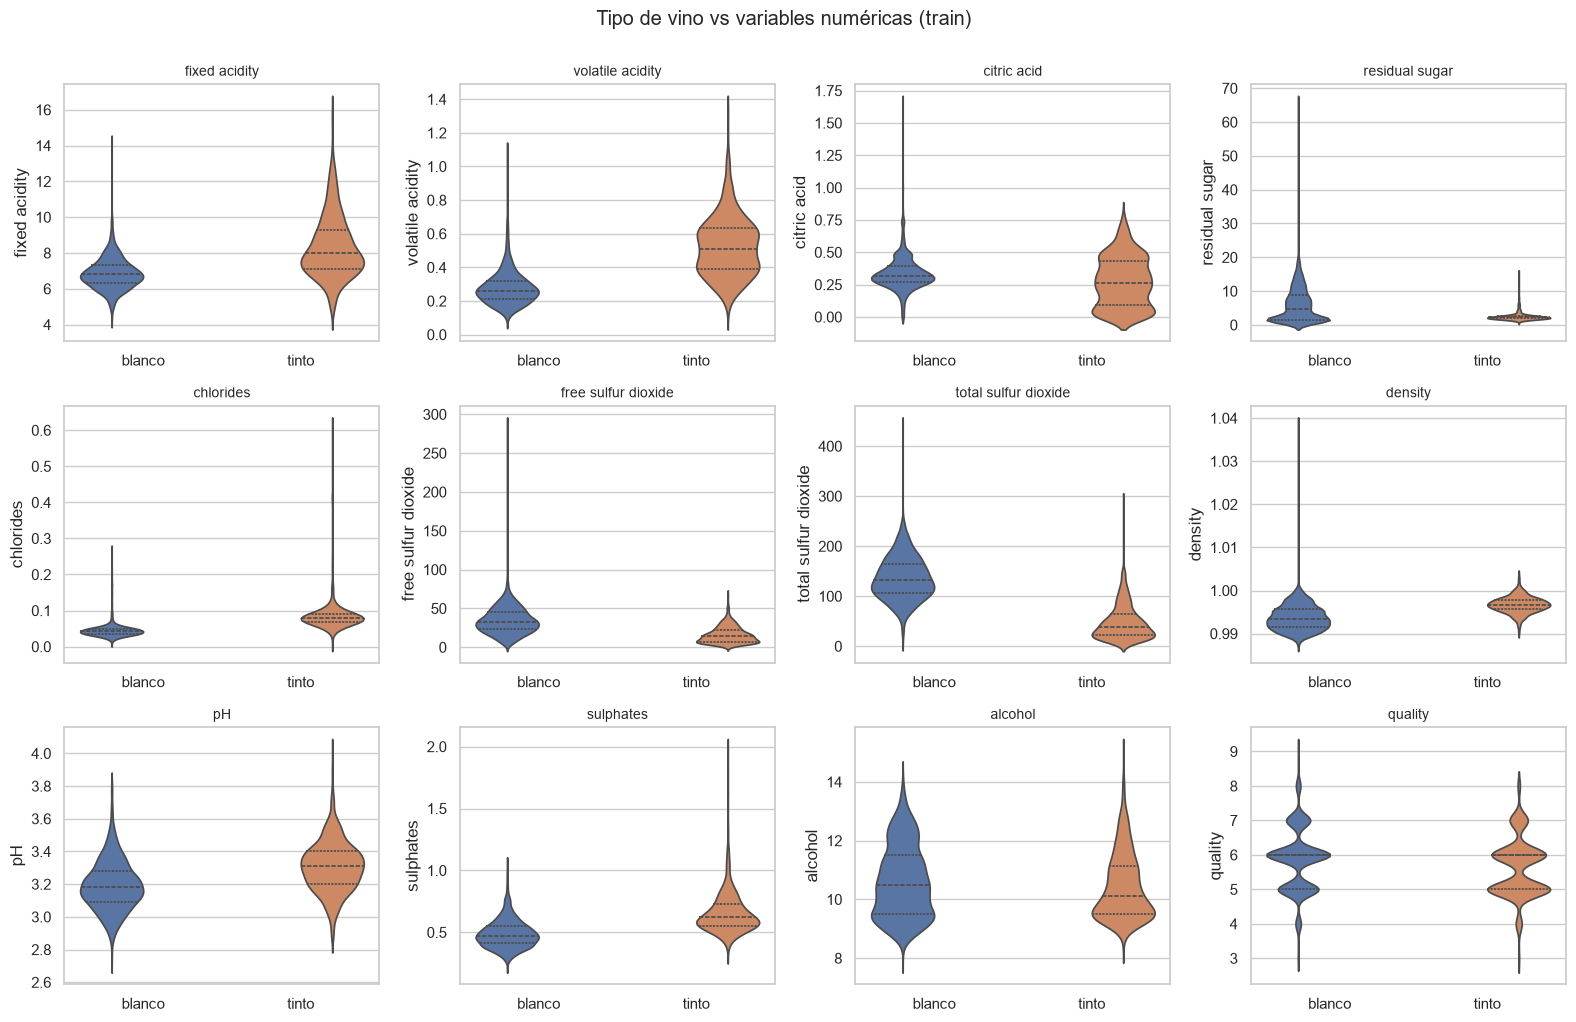

In [16]:
# Bivariable categórica vs numéricas: violin plots de 'tipo' contra cada variable
plot_cols = num_cols + [TARGET]
n_rows = int(np.ceil(len(plot_cols) / 4))
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 3.4 * n_rows), squeeze=False)
for ax, col in zip(axes.flat, plot_cols):
    sns.violinplot(data=df_train, x="tipo", y=col, hue="tipo", inner="quart",
                   legend=False, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
for ax in axes.flat[len(plot_cols):]:
    ax.set_visible(False)
fig.suptitle("Tipo de vino vs variables numéricas (train)", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "bivariate_tipo_vs_numeric.png", dpi=120); plt.show()

### Hallazgos del EDA

**1. El target está concentrado en el centro.** Las calidades 5 y 6 acumulan ≈77 % de las muestras y 4-7 el ≈96 %; los extremos casi no existen (3: 0.5 %, 9: 0.08 %).
*Interpretación:* el problema real no es distinguir vinos malos de excelentes, sino matices alrededor de la media. Un modelo entrenado con estos datos verá tan pocos vinos extremos que difícilmente aprenderá a reconocerlos, y cualquier métrica global estará dominada por las calidades medias; por eso incluso predecir siempre la media (dummy) ya logra un MAE de ≈0.70.

**2. Casi ninguna variable es normal.** Todas tienen asimetría positiva; las más extremas son `chlorides` (skew = 5.2), `residual sugar` (1.9), `fixed acidity` (1.7), `sulphates` (1.6), `free sulfur dioxide` (1.5) y `volatile acidity` (1.5). Las más cercanas a la normal son `total sulfur dioxide` (0.05, aunque bimodal), `pH` (0.4) y `citric acid` (0.5).
*Interpretación:* en las variables con cola derecha la media no representa el valor típico (la media de `residual sugar` la inflan unos cuantos blancos dulces). Esto justifica dos decisiones del flujo: imputar con **mediana** en lugar de media, y **normalizar** las distribuciones (Yeo-Johnson) antes de estandarizar, como pasos del pipeline (secciones 4 y 5).

**3. Ninguna variable predice la calidad por sí sola.** Las correlaciones más fuertes con `quality` son `alcohol` (+0.46), `density` (−0.32), `volatile acidity` (−0.25) y `chlorides` (−0.19); el resto queda por debajo de |0.11|.
*Interpretación:* tiene lectura de dominio: más alcohol suele indicar uvas más maduras y fermentación más completa (mejor calificación), mientras que la acidez volátil alta acerca el vino al vinagre (peor calificación). Pero ninguna correlación llega a 0.5: la calidad es un juicio sensorial multifactorial, así que la señal está repartida entre muchas variables débiles. Esto anticipa un techo bajo para cualquier modelo lineal simple y explica el R² modesto que se obtiene en la sección 6.

**4. Hay multicolinealidad fuerte entre features.** Los pares más correlacionados son `free`–`total sulfur dioxide` (+0.73), `alcohol`–`density` (−0.68), `density`–`chlorides` (+0.55), `total SO₂`–`residual sugar` (+0.50) y `density`–`fixed acidity` (+0.49).
*Interpretación:* no es casualidad sino física del vino: el SO₂ libre es parte del total, y la densidad depende directamente del alcohol (la baja) y del azúcar (la sube). La consecuencia práctica es que los **coeficientes** de la regresión lineal no deben interpretarse aisladamente (dos variables redundantes se reparten el efecto de forma inestable); la **predicción**, en cambio, no se ve afectada.

**5. Tinto y blanco son dos poblaciones químicas distintas.** Los violines muestran que el blanco tiene mucho más `total sulfur dioxide` (mediana ≈132 vs ≈39) y `residual sugar` (≈4.7 vs ≈2.2), mientras el tinto tiene más `volatile acidity`, `sulphates` (≈0.62 vs ≈0.47) y `chlorides` (≈0.079 vs ≈0.042).
*Interpretación:* varias rarezas del análisis univariable (la bimodalidad de `total SO₂`) no son propiedades de los vinos sino un artefacto de mezclar dos poblaciones. `tipo` aporta información real y se conserva como feature (one-hot). También sugiere que el efecto de algunas variables sobre la calidad podría ser distinto por tipo (interacciones), algo que la regresión lineal no captura y un modelo de árboles sí podría.

## 4. Limpieza de datos

Cada decisión se registra en `cleaning_log` (iniciado en la sección 2 con tipos y duplicados) para documentarla aquí y también en MLflow.

> **Nota:** en esta sección sólo se **diagnostica y se decide**, mirando únicamente el set de entrenamiento. Las transformaciones que dependen de estadísticas (imputación, normalización, estandarización) se integran como **pasos del pipeline del modelo** (sección 5): se aprenden de train en `fit()` y se aplican automáticamente, sin cambios, a validación y prueba al predecir.

In [17]:
# 4.1 Valores faltantes
print(f"Celdas faltantes -> train: {df_train.isna().sum().sum()} | "
      f"val: {df_val.isna().sum().sum()} | test: {df_test.isna().sum().sum()}")
# Wine Quality no tiene faltantes. Si llegaran a aparecer (p. ej. datos nuevos),
# el pipeline del modelo imputa mediana (numéricas) y moda (categóricas) ajustadas con train.
log_step("Faltantes", "Sin valores faltantes en ninguna partición; la imputación del pipeline queda como salvaguarda",
         len(df_train), len(df_train))

Celdas faltantes -> train: 0 | val: 0 | test: 0


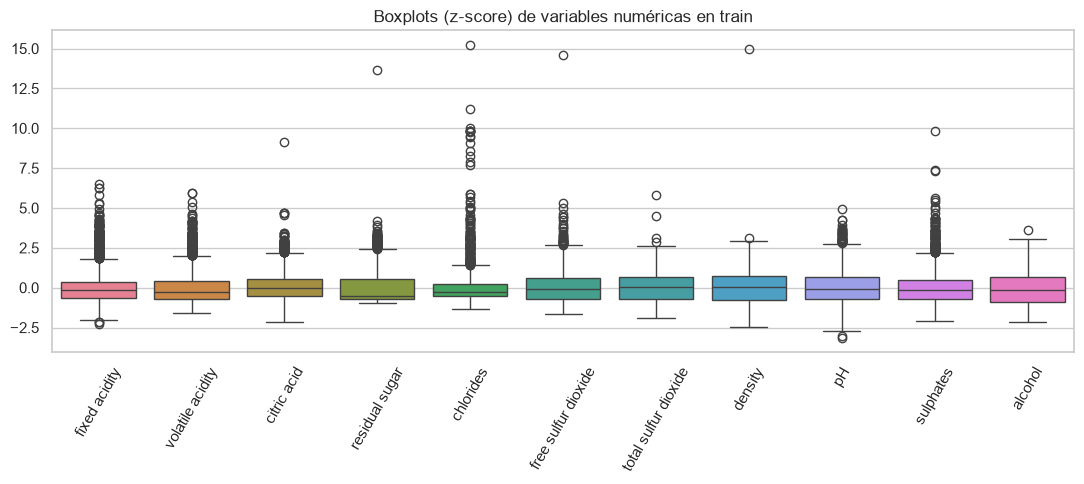

In [18]:
# 4.2 Outliers: inspección visual en train (boxplots sobre z-scores para comparar escalas)
z = (df_train[num_cols] - df_train[num_cols].mean()) / df_train[num_cols].std()
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=z, ax=ax)
ax.set_title("Boxplots (z-score) de variables numéricas en train")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(FIG_DIR / "numeric_boxplots.png", dpi=120); plt.show()

**Decisión sobre los outliers: se conservan.**

Los boxplots muestran valores extremos en varias variables (sobre todo `chlorides`, `volatile acidity`, `fixed acidity` y `sulphates`). **No se eliminan ni se recortan** porque son mediciones de laboratorio plausibles y propias del dominio (un vino blanco dulce tiene azúcar residual alta, un tinto puede ser naturalmente más salado), no errores de captura; descartarlos sería perder información real sobre vinos que el modelo debe aprender a calificar. Su influencia sobre la regresión se modera en el pipeline con la normalización Yeo-Johnson (4.3), que comprime las colas de las distribuciones sin eliminar ninguna muestra.

In [19]:
# Se registra la decisión (documentada arriba) en la bitácora de limpieza
OUTLIER_STRATEGY = "keep"
log_step("Outliers", "Se conservan: mediciones reales del dominio; su influencia se modera con la normalización Yeo-Johnson del pipeline",
         len(df_train), len(df_train))

In [20]:
# 4.3 Normalización y estandarización (decisión; el ajuste vive en el pipeline)
#
# - Normalización (PowerTransformer Yeo-Johnson): corrige la fuerte asimetría detectada
#   en el EDA acercando cada variable a una forma normal, lo que reduce la influencia de
#   las colas pesadas sin eliminar los outliers que decidimos conservar. Se prefiere sobre
#   MinMax porque MinMax depende del mínimo/máximo y es muy sensible justo a esos outliers,
#   y sobre una transformación log porque Yeo-Johnson admite ceros (citric acid los tiene).
# - Estandarización (StandardScaler, media 0 / desviación 1): pone todas las features en la
#   misma escala; los coeficientes de la regresión se vuelven comparables entre sí y el
#   pipeline queda listo para modelos que sí la requieren (regularizados o de gradiente).
#
# Evidencia: asimetría (skew) en train antes y después de Yeo-Johnson (ajustado sólo con train)
demo_yj = PowerTransformer(method="yeo-johnson", standardize=False).fit(df_train[num_cols])
skew_comp = pd.DataFrame({
    "skew_antes": df_train[num_cols].skew().round(2),
    "skew_despues": pd.DataFrame(demo_yj.transform(df_train[num_cols]),
                                 columns=num_cols).skew().round(2),
})
display(skew_comp)
log_step("Normalización y estandarización", "Yeo-Johnson + StandardScaler como pasos del pipeline, ajustados sólo con train",
         len(df_train), len(df_train))

,skew_antes,skew_despues
fixed acidity,1.66,-0.04
volatile acidity,1.48,0.11
citric acid,0.47,0.01
residual sugar,1.88,0.16
chlorides,5.24,0.21
free sulfur dioxide,1.51,-0.03
total sulfur dioxide,0.05,-0.17
density,0.90,0.00
pH,0.43,-0.00
sulphates,1.55,0.01


In [21]:
# 4.4 Columnas irrelevantes: no hay identificadores ni columnas que filtren el target;
# las 11 variables fisicoquímicas y 'tipo' son mediciones legítimas disponibles antes de la cata.
log_step("Columnas irrelevantes", "Ninguna: no hay IDs ni columnas con fuga de información",
         len(df_train), len(df_train))

In [22]:
# Resumen de la limpieza y guardado de las particiones.
# Se guardan tal como salieron del split: las transformaciones que dependen de
# estadísticas viven en el pipeline del modelo, no en los archivos.
cleaning_df = pd.DataFrame(cleaning_log)
for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    part.to_csv(PROCESSED_DIR / f"{name}.csv", index=False)
print(f"Particiones guardadas en {PROCESSED_DIR}")
cleaning_df

Particiones guardadas en C:\Users\yogue\Desktop\Tec\trimestre 4\MLOPs\Actividad 02 - notebook\data\processed


,paso,decision,filas_antes,filas_despues
0,Tipos,Numéricas y quality bien tipadas al cargar; 't...,6497,6497
1,Duplicados,Se eliminaron 1177 filas duplicadas exactas an...,6497,5320
2,Faltantes,Sin valores faltantes en ninguna partición; la...,3724,3724
3,Outliers,Se conservan: mediciones reales del dominio; s...,3724,3724
4,Normalización y estandarización,Yeo-Johnson + StandardScaler como pasos del pi...,3724,3724
5,Columnas irrelevantes,Ninguna: no hay IDs ni columnas con fuga de in...,3724,3724


### Justificación de las decisiones de limpieza

| Problema | Hallazgo | Decisión | Justificación |
|---|---|---|---|
| Tipos | Las 11 fisicoquímicas se leyeron como `float` y `quality` como `int` (correcto); `tipo` quedó como texto | Convertir `tipo` a `category` | Declara explícitamente su naturaleza categórica (2 valores), evita que se trate como texto libre y hace el one-hot del pipeline más robusto |
| Duplicados | 1,177 filas idénticas (18 % del dataset), esperables porque UCI documenta duplicados en este dataset | Eliminarlas **antes** de la partición | Si la misma muestra cae en train y en test, el modelo "ya vio" parte del test y las métricas salen infladas (*leakage*); además los duplicados sobre-ponderan esas muestras en el entrenamiento |
| Faltantes | 0 celdas faltantes en las tres particiones | Mantener imputación (mediana/moda) dentro del pipeline como salvaguarda | No altera estos datos, pero protege al modelo ante datos futuros incompletos; al vivir en el pipeline se ajusta sólo con train |
| Outliers | Valores extremos visibles en los boxplots, sobre todo en `chlorides`, `volatile acidity`, `fixed acidity` y `sulphates` | **Conservarlos** (`keep`) | Son mediciones reales del dominio (un blanco dulce tiene azúcar residual alta), no errores de captura; descartarlos perdería información válida. Su influencia se modera con la normalización Yeo-Johnson del pipeline |
| Asimetría (colas pesadas) | Distribuciones con fuerte cola derecha: `chlorides` (skew 5.2), `residual sugar` (1.9), `fixed acidity` (1.7), detectadas en el EDA | **Normalizar** con Yeo-Johnson, como paso del pipeline | La regresión lineal ajusta una sola recta global y los valores extremos que decidimos conservar actúan como puntos de alto apalancamiento que arrastran el ajuste lejos de donde vive la mayoría de los datos. Yeo-Johnson comprime las colas acercando cada distribución a la normal (skew de `chlorides`: 5.2 → 0.2) **sin eliminar ninguna muestra**, que era la restricción de la decisión de outliers. Se eligió sobre log (no admite los ceros de `citric acid`), Box-Cox (exige valores estrictamente positivos) y MinMax (es lineal: cambia la escala pero no corrige la forma de la distribución) |
| Unidades y escalas incomparables | Problema distinto al anterior: cada variable vive en su propia unidad y rango: `total sulfur dioxide` llega a cientos de mg/L mientras `density` varía en milésimas de g/cm³ | **Estandarizar** (media 0, desviación 1) después de normalizar, como paso del pipeline | Sin una escala común, la magnitud de cada coeficiente de la regresión refleja la unidad de medida de su variable, no su importancia: un coeficiente sobre `density` y uno sobre `total SO₂` no se pueden comparar. Estandarizar expresa todas las variables en la misma unidad (desviaciones estándar), vuelve comparables los coeficientes y deja el pipeline listo para los modelos que seguirían al baseline (Ridge/Lasso, métodos de gradiente), que sí son sensibles a la escala. Se ajusta sólo con train dentro del pipeline |

## 5. Modelo base (*baseline*)

**Modelo elegido: regresión lineal.** Es apropiada como baseline porque (1) el objetivo es numérico y la relación buscada es "cuánto vale la calidad", no "a qué clase pertenece"; (2) es el modelo más simple que usa todas las features, sin hiperparámetros que ajustar, por lo que el resultado es estable y reproducible; (3) entrena en milisegundos; y (4) fija el punto de referencia obligado: cualquier modelo más complejo (árboles, ensambles) tendrá que superarla para justificar su complejidad.
Se compara además contra un **modelo trivial** (`DummyRegressor`: predecir la media de train) para demostrar que el baseline aprende algo más que la tendencia central.

La partición 70/15/15 estratificada ya se realizó en la sección 2; aquí sólo se separan features y target. **Validación** sirve para comparar alternativas durante el desarrollo; **prueba** se reserva para la estimación final del desempeño.

In [23]:
# Separación de features y target por partición
X_train, y_train = df_train.drop(columns=[TARGET]), df_train[TARGET]
X_val, y_val = df_val.drop(columns=[TARGET]), df_val[TARGET]
X_test, y_test = df_test.drop(columns=[TARGET]), df_test[TARGET]
print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (3724, 12) | Val: (798, 12) | Test: (798, 12)


In [24]:
# Pipeline ÚNICO con todos los pasos de limpieza/preprocesamiento + el modelo.
# Todo se aprende SOLO de train al hacer fit(); predict() aplica exactamente los mismos
# pasos a cualquier partición (validación durante el desarrollo, test al final).
preprocessor = ColumnTransformer([
    # numéricas: imputación mediana (robusta a la asimetría del EDA)
    #   -> normalización Yeo-Johnson (corrige colas pesadas sin tocar outliers)
    #   -> estandarización (media 0 / desv 1: coeficientes comparables)
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("normalizer", PowerTransformer(method="yeo-johnson", standardize=False)),
                      ("scaler", StandardScaler())]), num_cols),
    # categóricas: imputación moda -> one-hot ('tipo' en columnas binarias para la regresión)
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

MODEL_PARAMS = {"fit_intercept": True}
estimator = LinearRegression(**MODEL_PARAMS)
dummy = DummyRegressor(strategy="mean")

model = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
model.fit(X_train, y_train)
dummy.fit(X_train, y_train)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['fixed acidity','volatile acidity','citric acid',...,'sulphates', 'alcohol','tipo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subs

## 6. Evaluación del modelo

Durante el desarrollo el modelo se compara contra **validación**; **prueba** se usa una sola vez, al final. Al llamar `predict()` sobre cada partición, el pipeline aplica automáticamente los mismos pasos aprendidos de train (imputación → normalización Yeo-Johnson → estandarización → one-hot), de modo que test recibe exactamente el mismo tratamiento sin intervención manual.

**Métrica principal: MAE (error absoluto medio).** Es coherente con el problema porque se interpreta directamente en las unidades del objetivo: "el modelo se equivoca en promedio X puntos de calidad", algo que un enólogo o un área de negocio entiende sin traducción. Además es robusta ante los pocos errores grandes que provocan las calidades extremas (3, 9), que son rarísimas en el dataset.
Se reportan como complemento el **RMSE** (penaliza más los errores grandes: si se aleja mucho del MAE hay fallas graves ocasionales) y el **R²** (proporción de la varianza de la calidad explicada por el modelo, útil para comparar contra el trivial, que por definición tiene R² = 0).

In [25]:
# Métricas por partición para el baseline y el modelo trivial
def evaluar(est, X_, y_) -> dict:
    pred = est.predict(X_)
    return {
        "mae": metrics.mean_absolute_error(y_, pred),
        "rmse": metrics.root_mean_squared_error(y_, pred),
        "r2": metrics.r2_score(y_, pred),
    }

results = pd.DataFrame({
    "baseline_train": evaluar(model, X_train, y_train),
    "baseline_val": evaluar(model, X_val, y_val),
    "baseline_test": evaluar(model, X_test, y_test),
    "dummy_val": evaluar(dummy, X_val, y_val),
    "dummy_test": evaluar(dummy, X_test, y_test),
}).round(4)
results

,baseline_train,baseline_val,baseline_test,dummy_val,dummy_test
mae,0.5610,0.5683,0.5571,0.6982,0.6957
rmse,0.7323,0.7410,0.7247,0.8887,0.8831
r2,0.3027,0.3047,0.3265,-0.0000,-0.0000


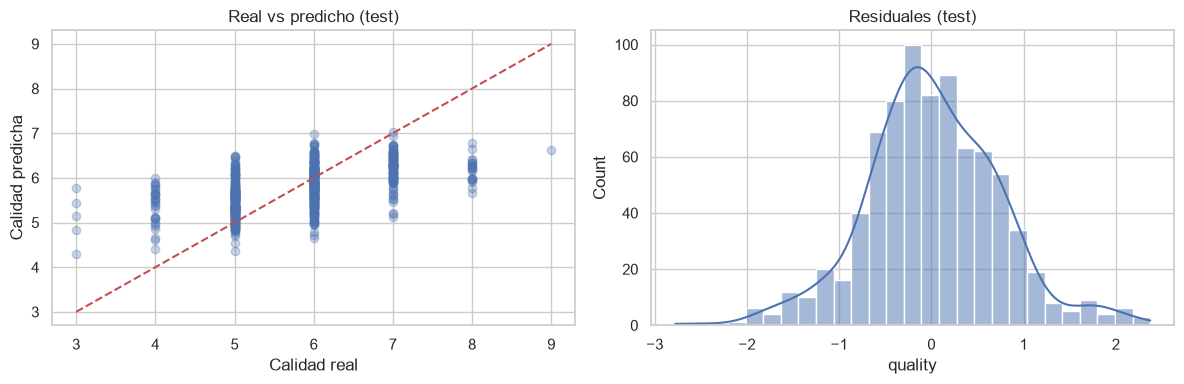

In [26]:
# Diagnóstico visual sobre la partición de prueba: real vs predicho y residuales
y_pred = model.predict(X_test)
eval_fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, y_pred, alpha=0.3)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--")
axes[0].set(xlabel="Calidad real", ylabel="Calidad predicha", title="Real vs predicho (test)")
sns.histplot(y_test - y_pred, kde=True, ax=axes[1])
axes[1].set_title("Residuales (test)")
eval_fig.tight_layout()
eval_fig.savefig(FIG_DIR / "evaluation.png", dpi=120)
plt.show()

### Interpretación de resultados

- **¿Qué significa el MAE?** En prueba el MAE es **0.557**: el modelo se equivoca en promedio ≈0.56 puntos de calidad en una escala donde el 96 % de los vinos vive entre 4 y 7. Es un error aceptable para un *filtro de cribado* (separar vinos probablemente malos de probablemente buenos antes de una cata), pero no sustituye al catador: confundir un 5 con un 6 es su error típico.
- **Contra el modelo trivial:** el dummy (predecir la media) obtiene MAE 0.696 y RMSE 0.883 en test; el baseline los reduce a 0.557 (−20 %) y 0.725 (−18 %), con R² = 0.33 contra 0.00. El baseline sí aprende estructura real de los datos, aunque la mayor parte de la varianza (67 %) sigue sin explicarse.
- **¿Sobreajuste o subajuste?** Las métricas son casi idénticas en las tres particiones (MAE: 0.561 train / 0.568 val / 0.557 test). No hay sobreajuste en absoluto; el problema es el contrario, **subajuste**: un modelo lineal es demasiado rígido para esta relación, consistente con que ninguna variable individual correlaciona fuerte con la calidad.
- **Patrones en los residuales:** la gráfica real-vs-predicho muestra que el modelo **comprime hacia la media**: casi todas las predicciones caen entre ≈5 y ≈6.5, por lo que subestima sistemáticamente los vinos de calidad 7-9 y sobreestima los de 3-4. Los residuales se concentran alrededor de 0 con forma aproximadamente simétrica, sin sesgo global, pero las "bandas" diagonales reflejan que el objetivo es discreto y el modelo predice valores continuos.
- **Limitaciones y siguiente paso:** la regresión lineal no captura interacciones ni relaciones no lineales (p. ej. el efecto del azúcar depende del tipo de vino). Mejoras esperables: ensambles de árboles (Random Forest / Gradient Boosting, que en la literatura llegan a MAE ≈ 0.42-0.45 en este dataset), features de interacción (p. ej. azúcar residual × tipo de vino), o replantear el problema como clasificación ordinal/binaria ("bueno" ≥ 7) si el caso de uso es de cribado.

## 7. Registro del experimento en MLflow

Se usa un backend local SQLite (`mlflow.db`) y artefactos en `mlartifacts/` en la raíz del proyecto.

In [27]:
# Configuración del tracking local
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=(ROOT / "mlartifacts").as_uri())
mlflow.set_experiment(EXPERIMENT_NAME)

<Experiment: artifact_location='file:///C:/Users/yogue/Desktop/Tec/trimestre%204/MLOPs/Actividad%2002%20-%20notebook/mlartifacts', creation_time=1791161455960, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791161455960, lifecycle_stage='active', name='TC5061_Actividad2_Baseline', tags={}, trace_location=None, workspace='default'>

In [28]:
# Registro de parámetros, métricas, artefactos y modelo
run_name = f"baseline_{type(estimator).__name__}"
with mlflow.start_run(run_name=run_name) as run:
    mlflow.set_tags({"etapa": "baseline", "problema": "regression", "autor": "Yoguel Salazar"})

    # Parámetros: datos, partición, limpieza y modelo
    mlflow.log_params({
        "dataset": "winequality red+white (UCI 186)", "target": TARGET,
        "n_rows_raw": df_raw.shape[0],
        "n_train": len(df_train), "n_val": len(df_val), "n_test": len(df_test),
        "split": "70/15/15 estratificado por quality", "random_state": RANDOM_STATE,
        "outlier_strategy": OUTLIER_STRATEGY,
        "scaling": "yeo-johnson + estandarizacion",
        "model": type(estimator).__name__, **{f"model__{k}": v for k, v in MODEL_PARAMS.items()},
    })

    # Métricas de todas las particiones (baseline y dummy)
    for col in results.columns:
        mlflow.log_metrics({f"{col}_{k}": float(v) for k, v in results[col].items()})

    # Artefactos: figuras y bitácora de limpieza
    mlflow.log_artifacts(str(FIG_DIR), artifact_path="figures")
    mlflow.log_table(cleaning_df, artifact_file="cleaning_log.json")

    # Modelo con firma de entrada/salida (formato skops: deserialización segura;
    # numpy.dtype lo usan los encoders y debe declararse como tipo confiable)
    signature = infer_signature(X_train, model.predict(X_train))
    mlflow.sklearn.log_model(model, name="model", signature=signature, input_example=X_train.head(3),
                             skops_trusted_types=["numpy.dtype"])

    print(f"Run ID: {run.info.run_id}")

Run ID: b69b2a582833466e9dd9d51d7294eacc


### Evidencia en la interfaz de MLflow

*Run `baseline_LinearRegression` en el experimento `TC5061_Actividad2_Baseline`. Primera captura: las 15 métricas registradas (baseline y dummy en train/val/test), tags y estado Finished. Segunda captura: la tabla de parámetros del run (dataset, tamaños de las particiones, semilla, estrategia de outliers, escalado y modelo) y el modelo guardado como artefacto.*

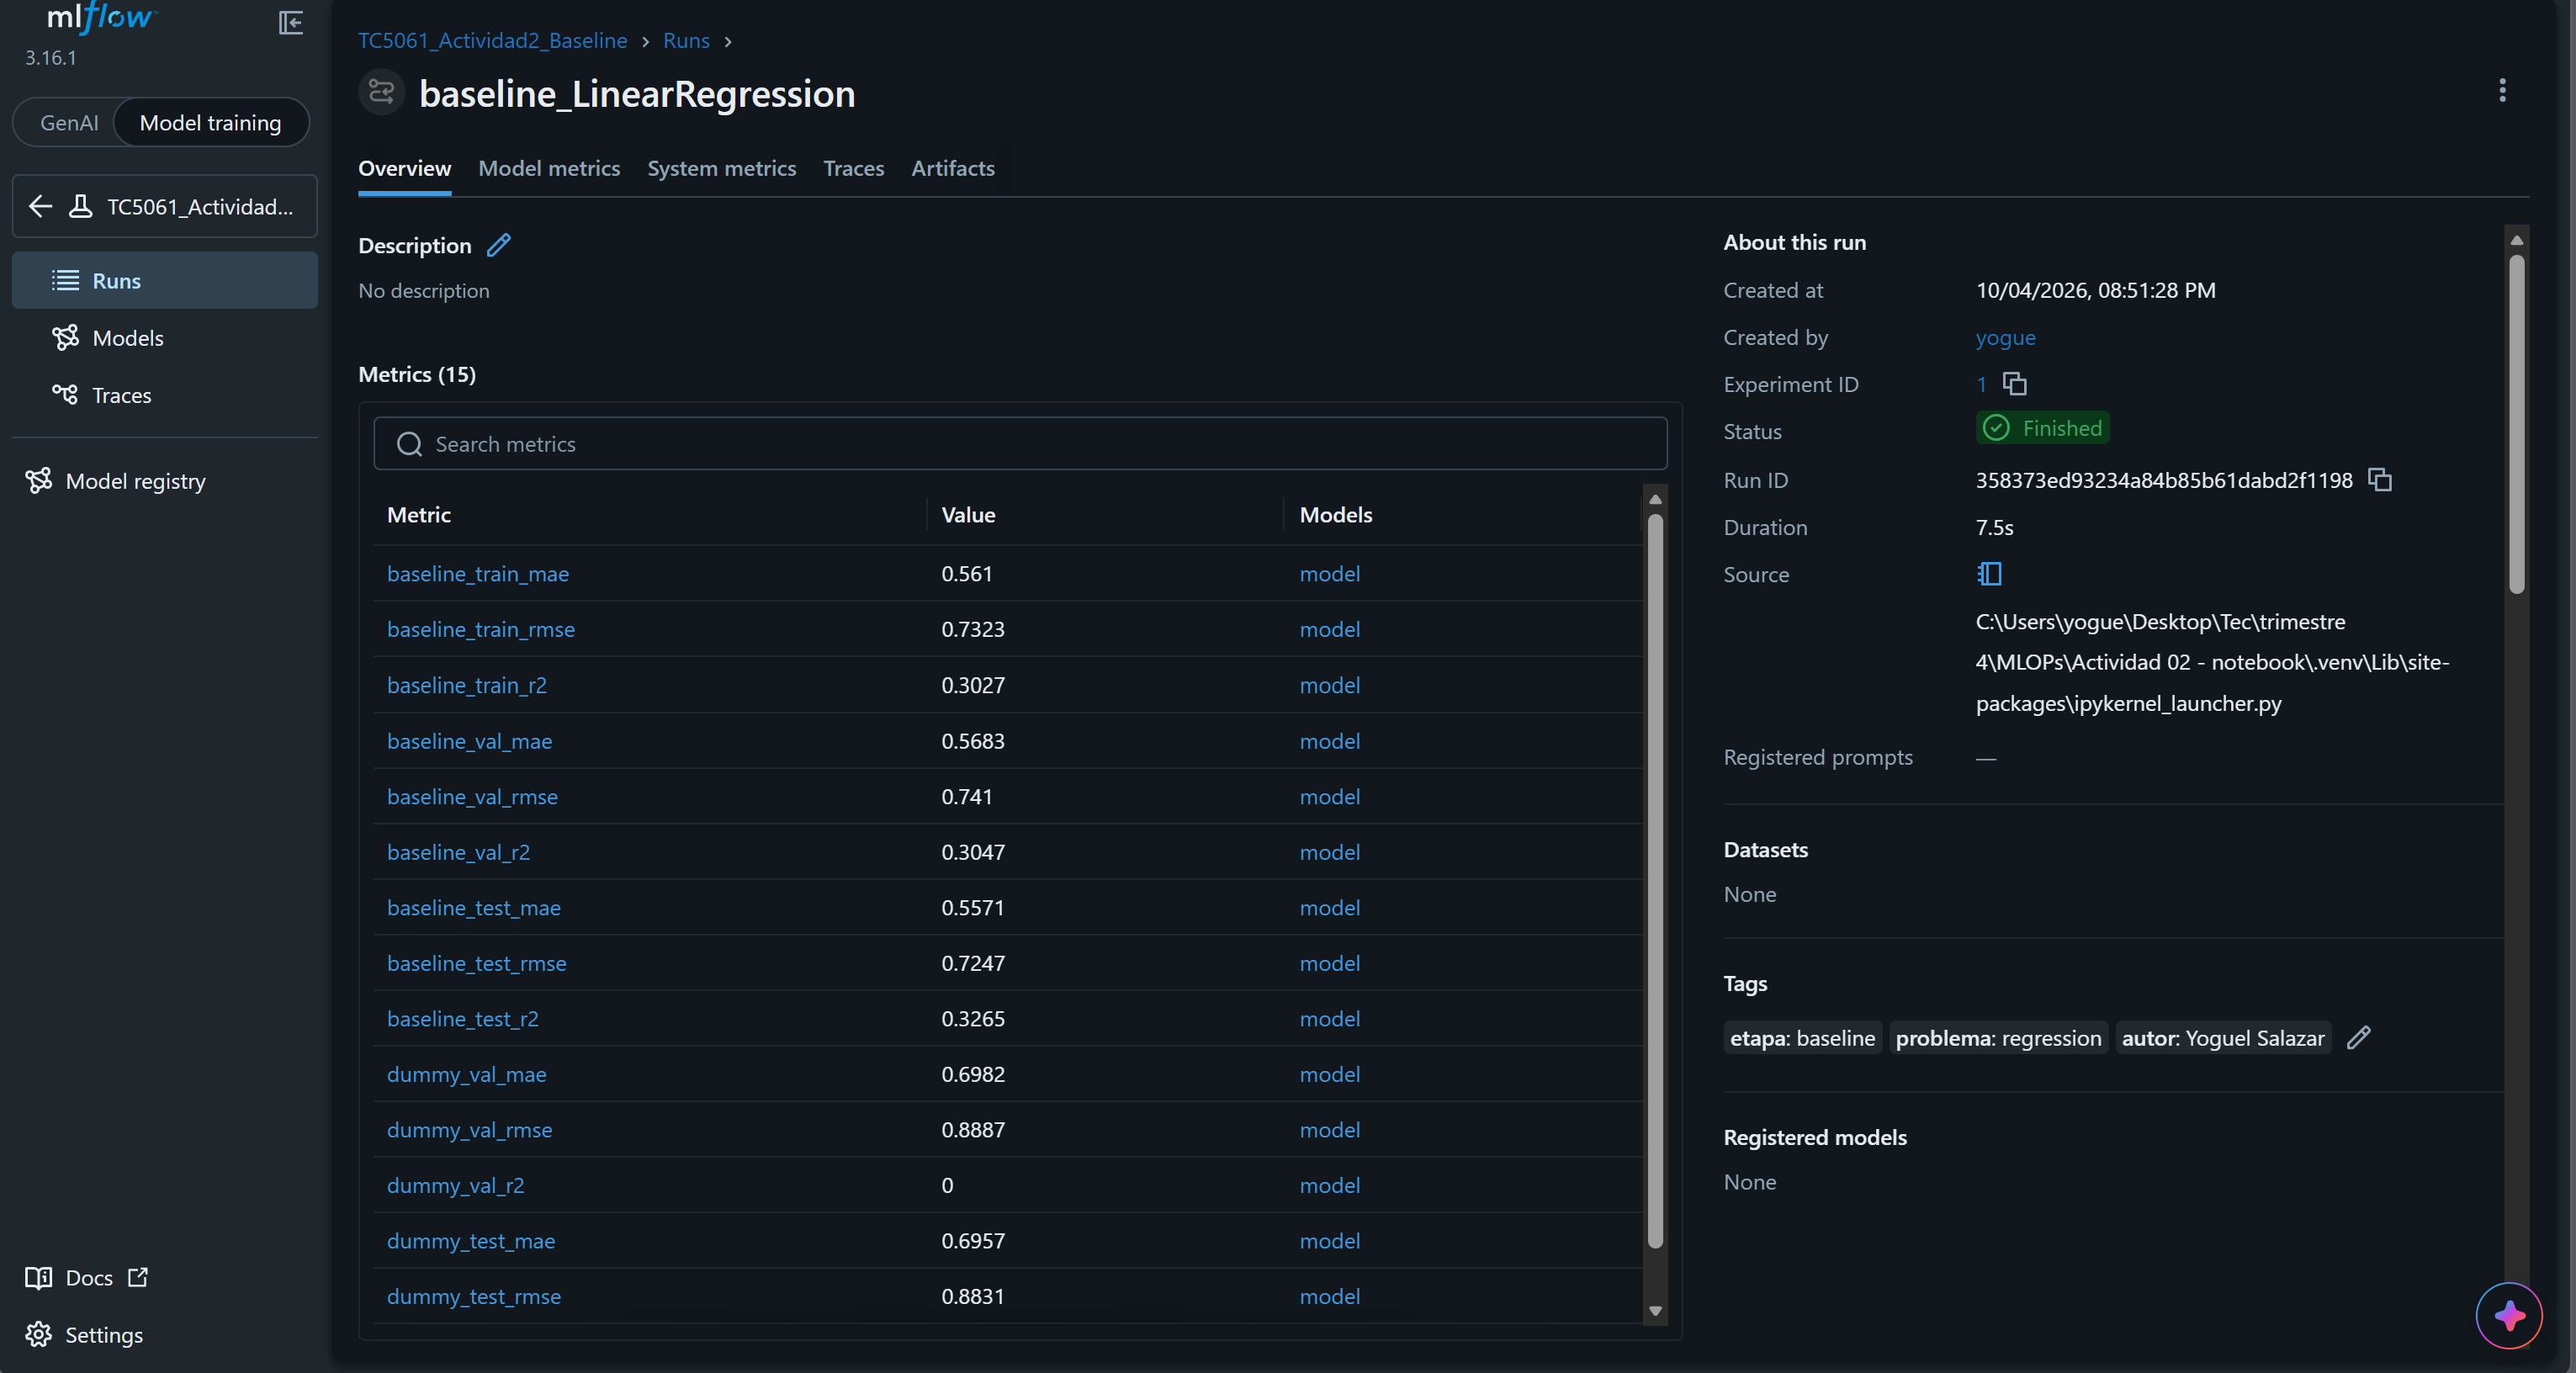

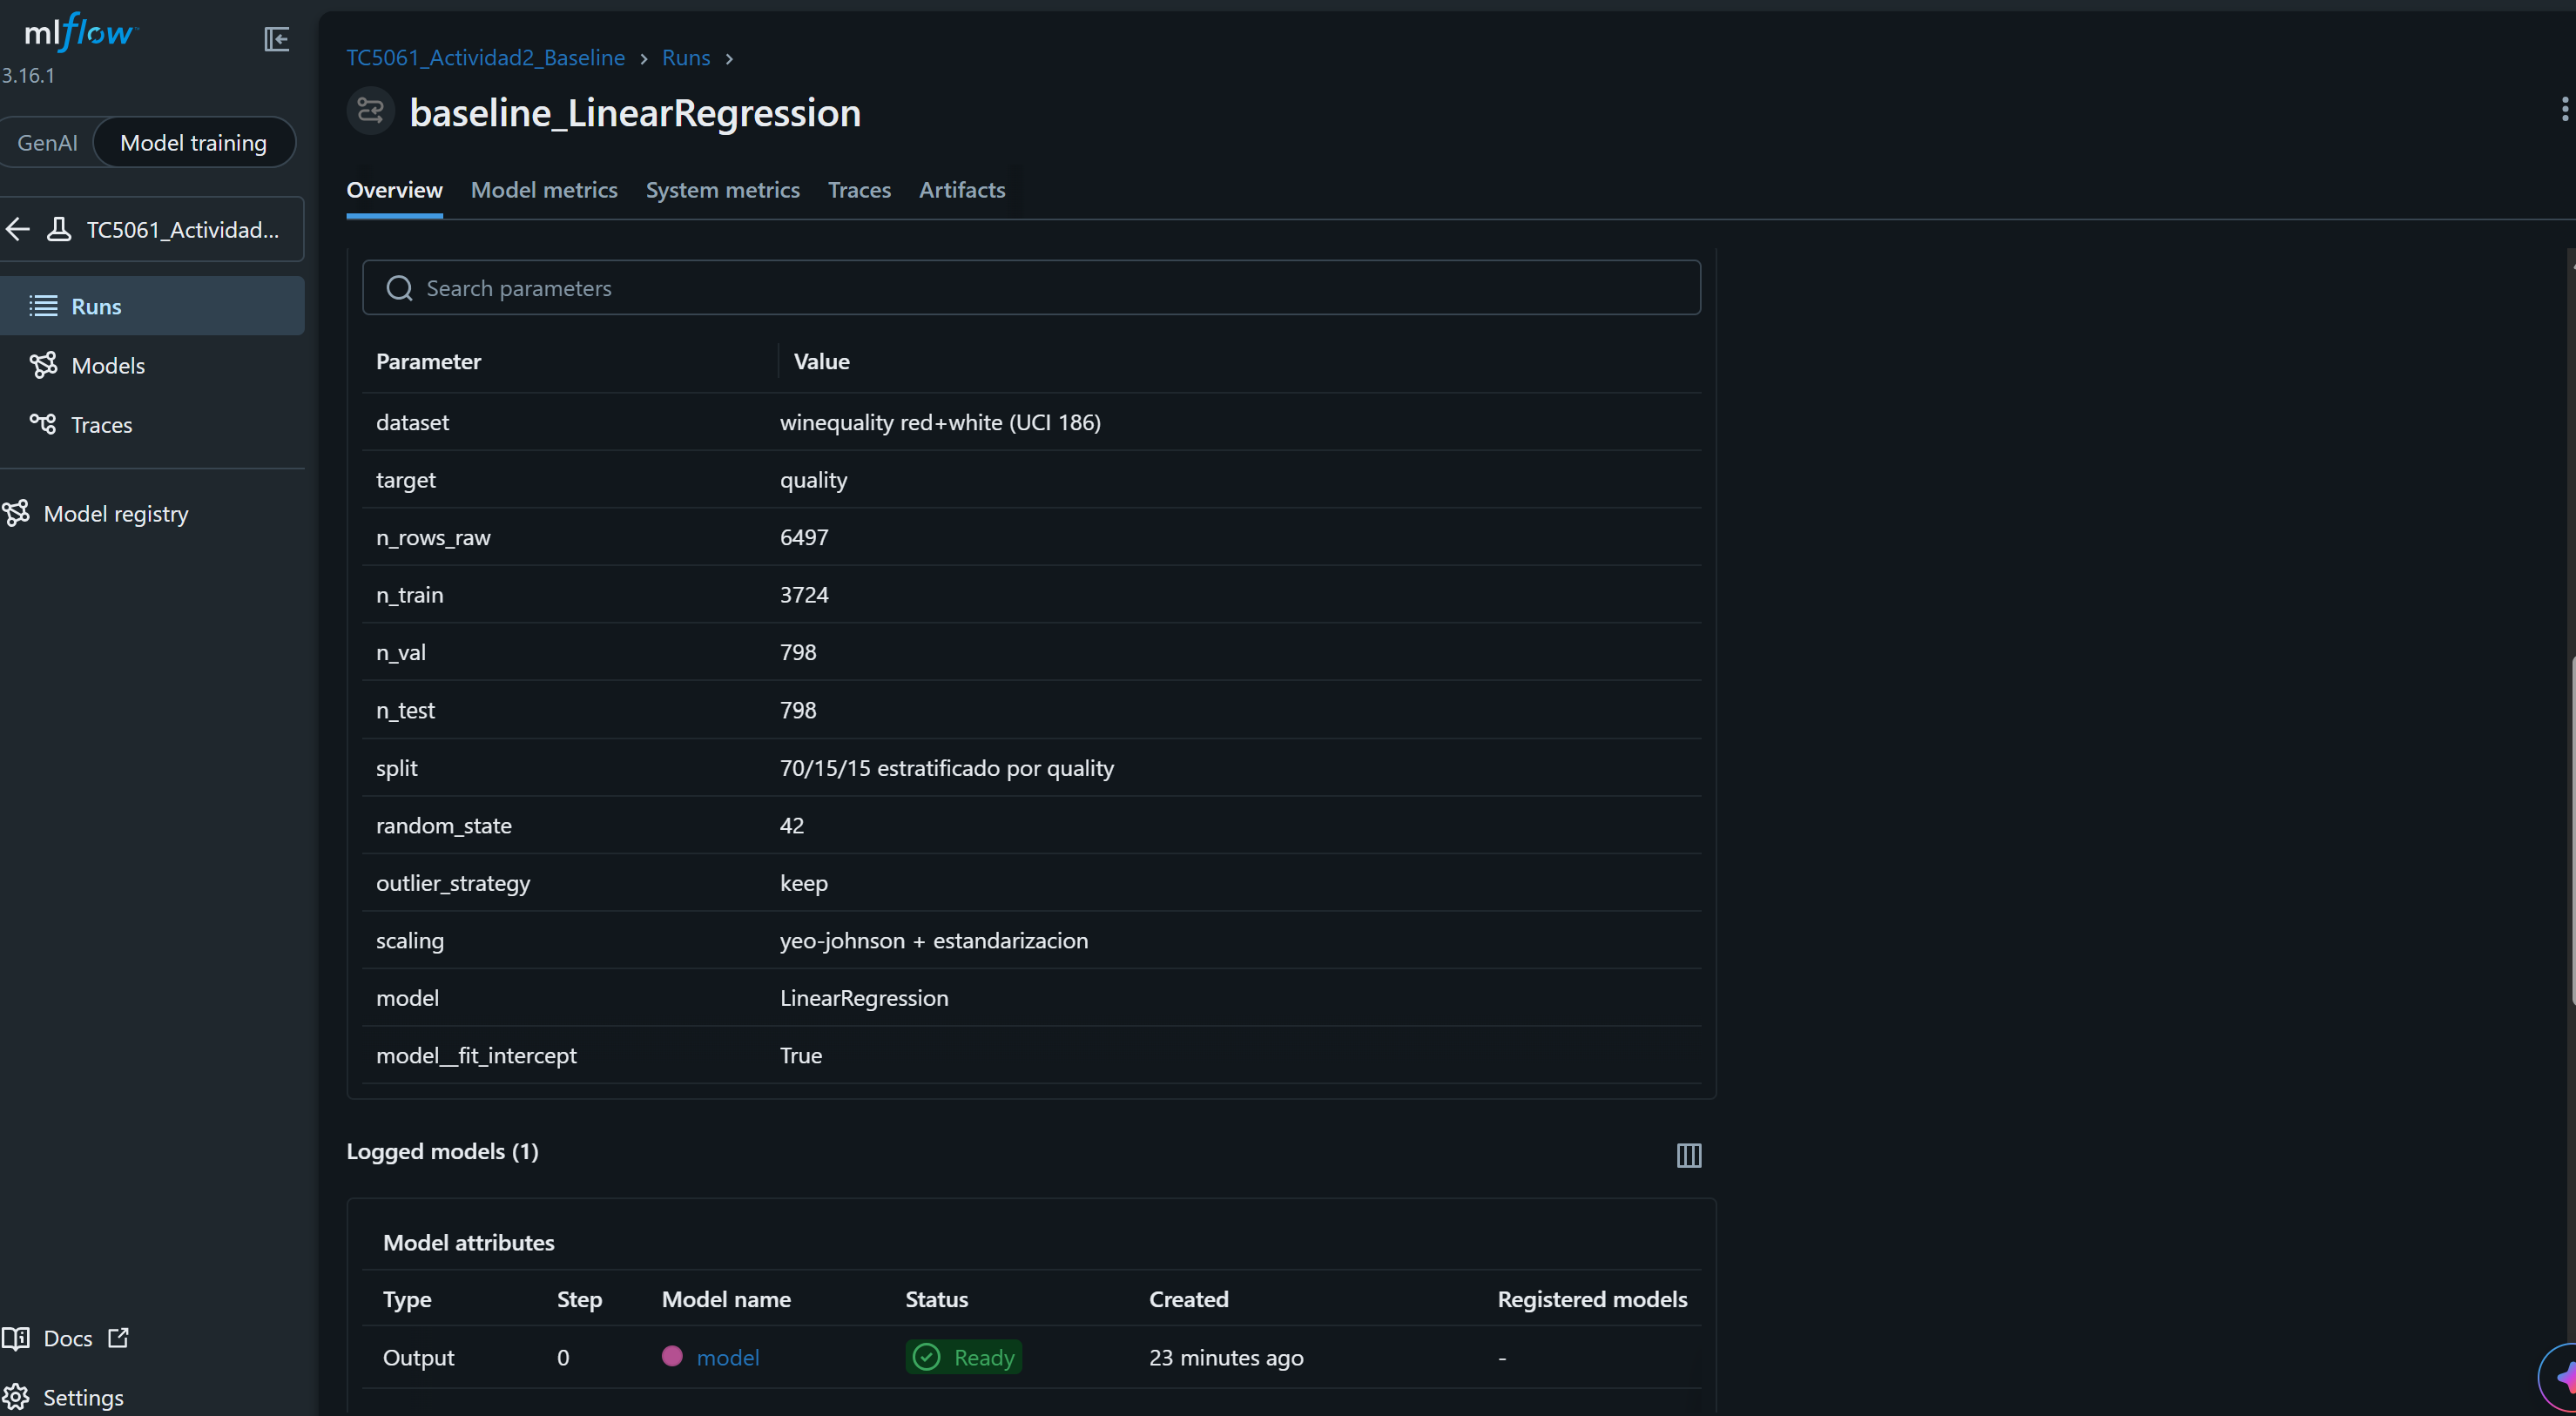

In [29]:
# Capturas de la interfaz de MLflow con el experimento registrado: métricas y parámetros.
# Se muestran como salidas de celda para que queden embebidas en el .ipynb
# y sean visibles en cualquier visor de notebooks.
from IPython.display import Image, display

display(Image(filename=str(ROOT / "reports" / "mlflow_screenshots" / "mlflow_run.png"), width=950))
display(Image(filename=str(ROOT / "reports" / "mlflow_screenshots" / "mlflow_run_params.png"), width=950))

## 8. Reflexión sobre MLOps

Este flujo me dio un punto de partida reproducible, pero varios de sus pasos siguen siendo manuales, y justo ahí es donde las prácticas de MLOps aportarían más valor. Los datos los descargué a mano de UCI y viven en una carpeta local: con **DVC** o un almacén versionado, el dataset y las particiones quedarían versionados junto al código, y cualquier persona podría reconstruir exactamente el mismo split 70/15/15 que usé. La limpieza vive en celdas del notebook: convertirla en un **pipeline modular** (scripts probados y versionados fuera del notebook) con **validaciones automáticas de calidad de datos** tipo Great Expectations evitaría que un CSV con esquema distinto o valores imposibles llegue al entrenamiento sin que nadie lo note; hoy nada lo detendría. Registré parámetros, métricas y artefactos en **MLflow Tracking**, y ese versionado de experimentos ya me resultó muy útil en la propia actividad: cada iteración del flujo quedó guardada como un run comparable, así que si quisiera seguir mejorando el modelo podría ir probando otros modelos o pipelines sin miedo a perder el registro de qué fui probando y con qué resultados. El siguiente paso natural es el **Model Registry**: versionar el modelo, promoverlo por etapas (*staging* → producción) y automatizar con **CI/CD** el reentrenamiento y la validación cuando lleguen datos nuevos, junto con **monitoreo de drift**, porque la relación entre química y calidad puede cambiar entre cosechas y proveedores. Finalmente, **contenerizar** el entorno con Docker eliminaría el clásico "en mi máquina sí funciona" que un `requirements.txt` solo mitiga a medias. En mi área profesional, el desarrollo de software, estos aprendizajes se reflejan de inmediato: versionar datos y experimentos es la extensión natural de la disciplina que ya aplicamos al código con Git y CI/CD, y me da un lenguaje común con los equipos de ciencia de datos para llevar modelos a producción de forma confiable y auditable.

## 9. Referencias

Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). *Wine Quality* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C56S3T

Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems, 47*(4), 547-553. https://doi.org/10.1016/j.dss.2009.05.016

## 10. Declaración de uso de inteligencia artificial

Anthropic. (2026). *Claude Code (basado en Claude Fable 5 y Claude Opus 5.5)* [Modelo de lenguaje grande], utilizado para generación de código y edición de texto. https://claude.com/claude-code